# Joint pace fit — fuel burn vs track evolution (E-10)

Lap times fall through a race for two reasons at once: the car burns fuel and the
track rubbers in. Fitting either alone absorbs the other's effect (the E-10 trap), so
the fit is joint: session, driver and compound fixed effects, a per-compound tyre-age
term, constructed fuel mass and lap number, estimated by ordinary least squares.

The catch is identifiability. Fuel is not observed — it is constructed, and in a race
with no interruption it is exactly a straight line in lap number, so the data cannot
say how much of the trend is fuel and how much is evolution. Safety-car laps bend the
fuel line (less burn behind the SC), which is the only within-race lever we have. The
fitter measures how strong that lever is (the fuel VIF) and refuses to attribute when
it is weak: `identified: false` means the circuit reports its combined trend and takes
the pooled k_m instead. Nothing is invented; the fitted trend always reproduces what
was observed.

In [1]:
import numpy as np
import pandas as pd

from senna import config
from senna.data.db import database_url, engine_for
from senna.physics.fits import frames, plots
from senna.physics.fits.gate import assert_quality_reports

fits_cfg = config.load("fits")
ingest_cfg = config.load("ingest")
CALIB = config.get(config.load("data_split"), "calibration_rounds")
SLICKS = ("SOFT", "MEDIUM", "HARD")

assert_quality_reports(
    config.get(ingest_cfg, "seasons"),
    config.REPO_ROOT / config.get(ingest_cfg, "quality.report_dir"),
)
engine = engine_for(database_url())
conn = await engine.connect()
index = await frames.circuit_index(conn, CALIB)
index[["slug", "era"]].drop_duplicates().groupby("era").size()

era
2024    25
2026     6
dtype: int64

In [2]:
from senna.physics.fits.fuel import session_fuel
from senna.physics.fits.joint_pace import fit_joint_pace

VIF_MAX = config.get(fits_cfg, "joint_pace.vif_max")
SC_BURN = config.get(fits_cfg, "fuel.sc_burn_factor")
fuel_by_era = {
    era: config.get(config.load(f"physics_{era}"), "mass.race_fuel_kg")
    for era in sorted(index["era"].unique())
}

fits, laps_cache = {}, {}
for era, allowance_kg in fuel_by_era.items():
    for slug in sorted(index.loc[index["era"] == era, "slug"].unique()):
        event_name = index.loc[index["slug"] == slug, "event_name"].iloc[0]
        laps = await frames.pace_laps(conn, event_name, era, CALIB)
        if laps.empty:
            continue
        laps = laps[laps["compound"].isin(SLICKS)]
        fuel_kg = session_fuel(laps, allowance_kg, SC_BURN)
        fits[(slug, era)] = fit_joint_pace(laps, fuel_kg, vif_max=VIF_MAX, calibration_rounds=CALIB)
        laps_cache[(slug, era)] = (laps, fuel_kg)

pd.DataFrame(
    {
        "circuit": slug,
        "era": era,
        "n_laps": f.n_laps,
        "t0_s": round(f.t0_s, 2),
        "trend_s_per_lap": round(f.trend_s_per_lap, 4),
        "vif_fuel": round(f.vif_fuel, 1),
        "condition": round(f.condition_number, 1),
        "identified": f.identified,
        "k_m_ols": None if f.k_m_ols_s_per_kg is None else round(f.k_m_ols_s_per_kg, 4),
        "k_m_ols_se": None if f.k_m_ols_se_s_per_kg is None else round(f.k_m_ols_se_s_per_kg, 4),
    }
    for (slug, era), f in sorted(fits.items())
)

,circuit,era,n_laps,t0_s,trend_s_per_lap,vif_fuel,condition,identified,k_m_ols,k_m_ols_se
0,abu_dhabi_grand_prix,2024,3028,90.67,-0.0561,87.6,2.040000e+01,False,0.0028,0.0031
1,australian_grand_prix,2024,852,83.67,-0.0505,170.6,1.460000e+01,False,-0.0115,0.0089
2,australian_grand_prix,2026,834,85.74,-0.0433,50.8,1.390000e+01,False,-0.0205,0.0106
3,austrian_grand_prix,2024,1435,70.67,-0.0313,131.7,1.510000e+01,False,0.0137,0.0051
4,azerbaijan_grand_prix,2024,1649,109.21,-0.0762,136.0,2.370000e+01,False,-0.0563,0.0087
5,bahrain_grand_prix,2024,1958,98.60,-0.0673,395.7,4.180000e+01,False,-0.1031,0.0090
6,belgian_grand_prix,2024,1010,108.62,-0.0920,1150.0,1.150000e+01,False,0.0124,0.0187
7,british_grand_prix,2024,802,94.02,-0.0554,121.6,1.820000e+01,False,0.0146,0.0058
8,canadian_grand_prix,2026,1369,77.15,-0.0327,23.6,1.310000e+01,True,0.0119,0.0093
9,chinese_grand_prix,2024,2400,100.16,-0.0742,70.9,1.580000e+01,False,-0.0061,0.0041


The collinearity table above is the deliverable's "collinearity reported" row: every
circuit-era carries its fuel VIF and design condition number into
`configs/physics_params.yaml`. Trends sit in the familiar −0.03 to −0.08 s/lap band.

In [3]:
from senna.physics.fits.joint_pace import pool_k_m

for era in fuel_by_era:
    era_fits = [f for (s, e), f in fits.items() if e == era]
    identified_pool = pool_k_m(era_fits)
    weak = [f for f in era_fits if f.k_m_ols_se_s_per_kg]
    weights = np.array([1 / f.k_m_ols_se_s_per_kg**2 for f in weak])
    values = np.array([f.k_m_ols_s_per_kg for f in weak])
    all_fits_pool = float((weights * values).sum() / weights.sum())
    print(
        f"era {era}: identified-only pool = {identified_pool}, "
        f"all-fits pool = {all_fits_pool:+.4f} s/kg over {len(weak)} circuits"
    )

era 2024: identified-only pool = None, all-fits pool = -0.0055 s/kg over 23 circuits
era 2026: identified-only pool = 0.011905103394271914, all-fits pool = -0.0016 s/kg over 5 circuits


The all-fits pool is the diagnostic that set the pooling rule. Pooling every weak
estimate gives a *negative* mass sensitivity — a heavier car cannot be faster, so the
weak estimates are not merely noisy, they are confounded: the post-interruption laps
that bend the fuel line also carry cold tyres, a bunched field and fresh rubber, and
the fit books those pace effects to fuel. The pooled k_m therefore uses identified
circuits only; an era with none borrows the other era's pool, flagged in the yaml as
a cross-era fallback.

/Users/saad/senna/docs/fits/joint_pace/bahrain_grand_prix_2024_residuals.png
/Users/saad/senna/docs/fits/joint_pace/canadian_grand_prix_2026_residuals.png


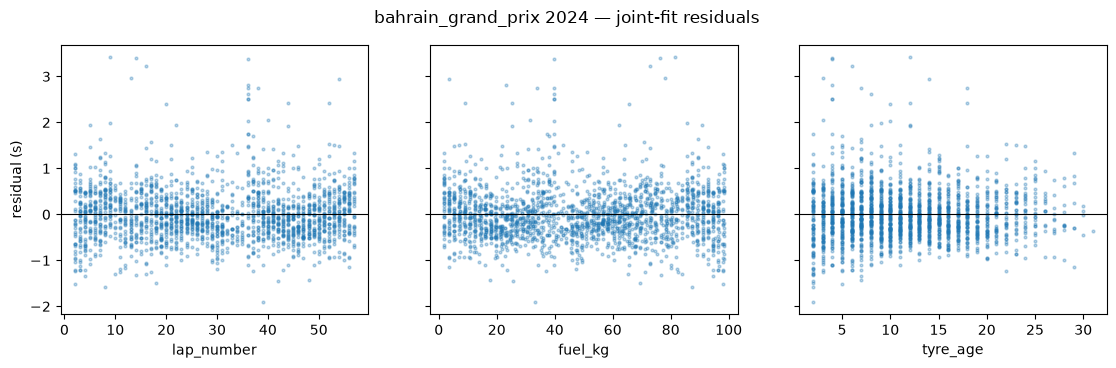

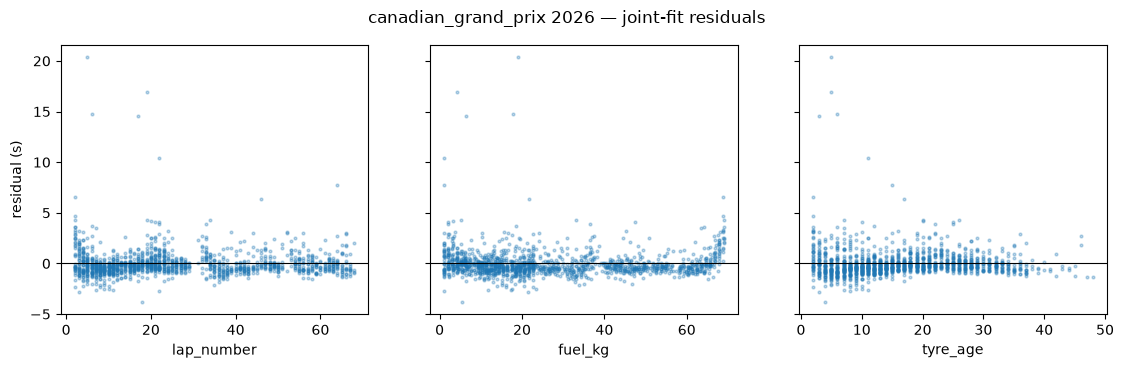

In [4]:
from senna.physics.fits.joint_pace import age_partial_residuals

for slug, era in [("bahrain_grand_prix", "2024"), ("canadian_grand_prix", "2026")]:
    laps, fuel_kg = laps_cache[(slug, era)]
    residuals = age_partial_residuals(laps, fuel_kg, calibration_rounds=CALIB)
    fig = plots.residual_panel(
        residuals["residual_s"],
        {
            "lap_number": residuals["lap_number"],
            "fuel_kg": residuals["fuel_kg"],
            "tyre_age": residuals["tyre_life"],
        },
        title=f"{slug} {era} — joint-fit residuals",
    )
    print(plots.save_figure(fig, "joint_pace", f"{slug}_{era}_residuals"))

In [5]:
rows = []
laps, _ = laps_cache[("canadian_grand_prix", "2026")]
for factor in (0.5, 0.6, 0.7):
    fuel_kg = session_fuel(laps, fuel_by_era["2026"], factor)
    fit = fit_joint_pace(laps, fuel_kg, vif_max=VIF_MAX, calibration_rounds=CALIB)
    rows.append(
        {
            "sc_burn_factor": factor,
            "k_m_s_per_kg": fit.k_m_s_per_kg,
            "vif_fuel": round(fit.vif_fuel, 1),
            "identified": fit.identified,
        }
    )
pd.DataFrame(rows)

,sc_burn_factor,k_m_s_per_kg,vif_fuel,identified
0,0.5,0.012456,23.5,True
1,0.6,0.011905,23.6,True
2,0.7,0.011356,23.8,True


Sensitivity of the one identified circuit to the stylised `sc_burn_factor`: the
attribution moves with the assumed SC burn saving, which is why the factor lives in
`configs/fits.yaml` with its origin stated rather than hiding in code.

In [6]:
await conn.close()
await engine.dispose()